In [1]:
# !export CUDA_VISIBLE_DEVICES=1
import torch
import torch.nn as nn
import os
import numpy as np

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

import pandas as pd
import json

import wandb

from copy import deepcopy

from cmcrameri import cm


# Configure matplotlib to use LaTeX for r'' strings while keeping other text unchanged
mpl.rcParams.update({
    'text.usetex': True,          # Use LaTeX for r'' strings
    'font.family': 'sans-serif',  # Default font family for regular text
    'mathtext.fontset': 'dejavusans',  # Font for math not using r''
    'axes.formatter.use_mathtext': False  # Enable math text for tick labels
})

In [2]:
# set random seed
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)
set_seed(42)

In [4]:
from plot_utils import extract_all_results, results_to_dataframe, \
    plot_advanced_comparison, plot_comparison, method_names, method_colors

In [5]:
from repl.networks.utils import additional_data_process, prepare_model
from repl.scripts.utils import (
    get_data_specs,
    prepare_data,
)

from repl.scripts.eval_utils import get_repl_representation

In [6]:
api = wandb.Api()

In [16]:
savedir = '../RPL_figures/5_real_world_data'
if not os.path.exists(savedir):
    os.makedirs(savedir)

# Mouse dataset

In [ ]:
input_size, num_classes = get_data_specs(dataset="mouse",
                                        target_label="multitask",
                                        flatten_images=False)

(train_loader, train_sampler, 
    _, _,
        test_loader, test_sampler,
    ) = prepare_data(
            dataset="mouse",
            data_input_dir="../datasets",
            seq_len=25,
            num_workers=0,
            batch_size=128,
            val_batch_size=128,
            grayscale=True,
            target_label="multitask",
        )

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
path_to_models = "../checkpoints"
pred_model_paths = [f"mouse_pred_{i}" for i in range(1,4)]
inv_model_paths = [f"mouse_inv_sg_{i}" for i in range(1,4)]
random_model_paths = ["mouse_random_1"]

In [ ]:
preprocess, postprocess = additional_data_process("mouse", None, None, flatten_enc_output=True)
n_in_channels = 1

models = {"pred_1": None, "pred_2": None, "pred_3": None, "inv_sg_1": None, "inv_sg_2": None, "inv_sg_3": None, "random_1": None}
for model_name in models.keys():
    if "pred" in model_name:
        model_path = pred_model_paths[int(model_name.split("_")[-1]) - 1]
    elif "inv_sg" in model_name:
        model_path = inv_model_paths[int(model_name.split("_")[-1]) - 1]
    elif "random" in model_name:
        model_path = random_model_paths[int(model_name.split("_")[-1]) - 1]

    pred_target = "pred" if model_name.startswith("inv") else "enc"
    
    full_model_path = os.path.join(path_to_models, model_path)
    model = deepcopy(prepare_model(
        encoder_kind="conv2d",
        integrator_kind="lstm",
        predictor_kind="mlp",
        input_size=input_size,
        enc_dim=32,
        ctx_dim=256,
        pred_n_hidden_layers=1,
        pred_hidden_dim=256,
        pred_steps=1,
        prediction_target="pred",
        use_bn_enc=True,
        enc_n_layers=6,
        enc_kernel_size=[(5, 5)] * 3 + [(3, 3)] * 3,
        enc_stride=[(2, 2)] * 3 + [(1, 1)] * 3,
        enc_padding=[(2, 2)] * 3 + [(1, 1)] * 3,
        preprocess=preprocess,
        postprocess=postprocess,
        n_in_channels=n_in_channels,
        flatten_enc_output=True,
        return_full_features=True,
        state_dict=torch.load(os.path.join(full_model_path, "model_final.pt"))
    )).to(device)
    models[model_name] = model

In [ ]:
def get_readout_data(models, train_loader, test_loader, device):
    """Extract readout data from models for train and test sets."""
    labels_to_keep = [0, 1, 6, 7, 12, 13, 14, 15]
    data = {}
    for model_name, model in models.items():
        readout_train_data, (_, readout_train_dense_labels) = get_repl_representation(
            train_loader,
            model,
            downstream_input="ctx",
            label_types=(2, 3),
            device=device,
        )
        readout_test_data, (_, readout_test_dense_labels) = get_repl_representation(
            test_loader,
            model,
            downstream_input="ctx",
            label_types=(2, 3),
            device=device,
        )
        data[model_name] = {
            "train_X": readout_train_data,
            "train_Y": readout_train_dense_labels[:, :, labels_to_keep],
            "test_X": readout_test_data,
            "test_Y": readout_test_dense_labels[:, :, labels_to_keep],
        }
    return data

In [ ]:
def get_scores(data, regressor_type="LinearRegression", **params):
    """Compute regression scores for each model's readout data."""
    from repl.scripts.eval_utils import get_linear_regression_metrics
    from sklearn.linear_model import LinearRegression, Ridge

    scores = {}
    for model_name, model_data in data.items():
        readout_train_data = model_data["train_X"]
        readout_train_dense_labels = model_data["train_Y"]
        readout_test_data = model_data["test_X"]
        readout_test_dense_labels = model_data["test_Y"]

        n_features = readout_train_data.shape[-1]
        n_dense_labels = readout_train_dense_labels.shape[-1]

        if regressor_type == "LinearRegression":
            regressor = LinearRegression()
        elif regressor_type == "Ridge":
            regressor = Ridge(**params)
        else:
            raise ValueError(f"Unknown regressor type: {regressor_type}")

        regressor.fit(readout_train_data.reshape((-1, n_features)), readout_train_dense_labels.reshape((-1, n_dense_labels)))
        regression_loss_train, r2_score_train = get_linear_regression_metrics(
            readout_train_data.reshape((-1, n_features)),
            readout_train_dense_labels.reshape((-1, n_dense_labels)),
            regressor
        )
        regression_loss_test, r2_score_test = get_linear_regression_metrics(
            readout_test_data.reshape((-1, n_features)),
            readout_test_dense_labels.reshape((-1, n_dense_labels)),
            regressor
        )
        scores[model_name] = {
            "train_loss": regression_loss_train,
            "train_r2": r2_score_train,
            "test_loss": regression_loss_test,
            "test_r2": r2_score_test,
        }
    return scores

In [ ]:
n_dense_labels = len(num_classes[3])

readout_data = get_readout_data(models, train_loader, test_loader, device)

In [ ]:
var_names = ["Nose_x", "Tailroot_x", "Nose_y", "Tailroot_y", "Tailroot_xvel", "Tailroot_yvel", "sin", "cos"]

In [ ]:
import matplotlib
matplotlib.rc('text', usetex=True)
matplotlib.rc('text.latex', preamble=r'\usepackage{amsmath}')  # for boldsymbol

In [ ]:
metric_configs = {
    'r2': {
        'averaged_tasks': [
            {
                'tasks': ["Nose_x", "Nose_y"],
                'name': r'$\boldsymbol{r}_N$'
            },
            {
                'tasks': ["Tailroot_xvel", "Tailroot_yvel"],
                'name': r'$\boldsymbol{v}_T$'
            },
            {
                'tasks': ["sin", "cos"],
                'name': r'$\theta$'
            },
        ],
    },
}

In [ ]:
original_train_Y = {model_name: deepcopy(readout_data[model_name]["train_Y"]) for model_name in readout_data.keys()}
original_test_Y = {model_name: deepcopy(readout_data[model_name]["test_Y"]) for model_name in readout_data.keys()}

In [ ]:
for model_name in readout_data.keys():
    x_T_train = readout_data[model_name]["train_Y"][:, :, 1]
    y_T_train = readout_data[model_name]["train_Y"][:, :, 3]
    x_T_test = readout_data[model_name]["test_Y"][:, :, 1]
    y_T_test = readout_data[model_name]["test_Y"][:, :, 3]
    readout_data[model_name]["train_Y"][:, :, 5] = np.cumsum(np.gradient(x_T_train, axis=1), axis=1)
    readout_data[model_name]["train_Y"][:, :, 7] = np.cumsum(np.gradient(y_T_train, axis=1), axis=1)
    readout_data[model_name]["test_Y"][:, :, 5] = np.cumsum(np.gradient(x_T_test, axis=1), axis=1)
    readout_data[model_name]["test_Y"][:, :, 7] = np.cumsum(np.gradient(y_T_test, axis=1), axis=1)

In [ ]:
scores = get_scores(readout_data, regressor_type="Ridge", alpha=1.0)

In [ ]:
df = pd.DataFrame(columns=["dataset", "method", "task", "seed", "r2"])
for model_name, model_scores in scores.items():
    seed = int(model_name.split("_")[-1])
    method = model_name[:-2]
    if method == "random":
        method = "rand"
    for label_idx in range(len(var_names)):
        r2 = model_scores["test_r2"][label_idx]
        df = pd.concat([df, pd.DataFrame({
            "dataset": ["mouse"],
            "method": [method],
            "task": [var_names[label_idx]],
            "seed": [seed],
            "r2": [r2],
        })], ignore_index=True)

In [ ]:
fig, axes = plot_advanced_comparison(
    results_df=df,
    methods_to_plot=['pred', 'inv_sg'],
    baseline_methods=['rand'],
    metric_configs=metric_configs,
    method_names=method_names,
    method_colors=method_colors,
    dataset="mouse",
    figsize=(2.2, 0.8),
    plot_spacing=0.25,
    ylim=(-0.05, 1.05),
    point_size=10,
    sharey=True,
    # loc_legend=(1.05, -0.1),
    display_legend=False
)
for ax in axes:
    ax.set_ylim(-0.1, 0.75)
# save figure
fig.savefig(os.path.join(savedir, "mouse_perf_dpos_cumsum_ridge.pdf"), bbox_inches='tight', dpi=300, transparent=True)

# LibriSpeech

In [15]:
datasets = ['libri_delta8']

print(datasets)

method_map = {
    'rand': 'random',
    'pred': 'pred',
    'inv_sg': 'inv_sg',
}

# Extract results with both accuracy and r2 metrics
results = extract_all_results(datasets=datasets, method_map=method_map, wandb_project="RPL", remove_offline=True)

# Convert to DataFrame
results_df = results_to_dataframe(results)

['libri_delta8']
No exact match found for method_key: supervised
No exact match found for method_key: pred_vcreg
No exact match found for method_key: pred_vcreg
No exact match found for method_key: pred_vcreg
No exact match found for method_key: pred_vcreg
No exact match found for method_key: pred_vcreg
No exact match found for method_key: pred_vcreg
No exact match found for method_key: phoneme_enc_pred_ctx_target
No exact match found for method_key: phoneme_enc_pred_ctx_target
No exact match found for method_key: speaker_enc_pred_ctx_target
No exact match found for method_key: speaker_enc_pred_ctx_target
No exact match found for method_key: speaker_enc_pred_ctx_target
No exact match found for method_key: speaker_enc_inv
No exact match found for method_key: inv
No exact match found for method_key: phoneme_enc_inv
No exact match found for method_key: speaker_enc_inv
No exact match found for method_key: phoneme_enc_inv
No exact match found for method_key: inv
No exact match found for met

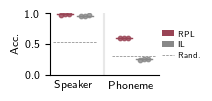

In [17]:
fig, axs = plot_comparison(results_df, 
                    methods_to_plot=['pred', 'inv_sg'],
                    baseline_methods=['rand'],
                    task_names={'seq2label': 'Speaker', 'seq2seq': 'Phoneme'},
                    method_names=method_names,
                    method_colors=method_colors,
                    figsize=(1.4, 0.8),
                    dataset='libri_delta8',
                    ylim=(0., 1.0),
                    loc_legend=(1.0, 0.2),
                    display_legend=True,
                    display_xticks=True,
                    legend_ax_idx=1,
                    point_size=10,
                    sharey=True)
fig.savefig(os.path.join(savedir, 'libri_ctx_comparison.pdf'), bbox_inches='tight', dpi=300, transparent=True)